<a href="https://colab.research.google.com/github/khadija570/memory-augmented-autoresearch-/blob/main/01_environment_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / 1024**3
    )

    print(f"GPU Memory: {gpu_memory:.2f} GB")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB
Device: cuda


In [5]:
!nvidia-smi

Sun Nov 22 21:29:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
!pip -q install datasets transformers tiktoken

In [7]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [8]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/memory-augmented-autoresearch"
)

folders = [
    "notebooks",
    "src",
    "data",
    "configs",
    "results",
    "checkpoints",
    "research",
    "tests"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project directory:", PROJECT_DIR)

for folder in PROJECT_DIR.iterdir():
    print(folder.name)

Project directory: /content/drive/MyDrive/memory-augmented-autoresearch
notebooks
src
data
configs
results
checkpoints
research
tests


In [9]:
from datasets import load_dataset

DATASET_NAME = "roneneldan/TinyStories"

train_stream = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True
)

validation_stream = load_dataset(
    DATASET_NAME,
    split="validation",
    streaming=True
)

print("Dataset loaded successfully!")

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

Dataset loaded successfully!


In [10]:
from itertools import islice

N_TRAIN = 10000
N_VALIDATION = 1000
N_TEST = 1000

train_iterator = iter(train_stream)

train_samples = list(
    islice(train_iterator, N_TRAIN)
)

validation_iterator = iter(validation_stream)

validation_samples = list(
    islice(validation_iterator, N_VALIDATION)
)

test_samples = list(
    islice(validation_iterator, N_TEST)
)

print("Training samples:", len(train_samples))
print("Validation samples:", len(validation_samples))
print("Test samples:", len(test_samples))

Training samples: 10000
Validation samples: 1000
Test samples: 1000


In [11]:
# explore data
import pandas as pd

df_train = pd.DataFrame(train_samples)

print("Dataset shape:", df_train.shape)
print("Columns:", df_train.columns.tolist())

display(df_train.head())

Dataset shape: (10000, 1)
Columns: ['text']


,text
0,"One day, a little girl named Lily found a need..."
1,"Once upon a time, there was a little car named..."
2,"One day, a little fish named Fin was swimming ..."
3,"Once upon a time, in a land full of trees, the..."
4,"Once upon a time, there was a little girl name..."


In [12]:
print(df_train.iloc[0]["text"])

One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.


In [13]:
df_train["char_count"] = (
    df_train["text"].str.len()
)

df_train["word_count"] = (
    df_train["text"].str.split().str.len()
)

display(
    df_train[
        ["char_count", "word_count"]
    ].describe()
)

print(
    "Missing texts:",
    df_train["text"].isna().sum()
)

print(
    "Duplicate texts:",
    df_train["text"].duplicated().sum()
)

,char_count,word_count
count,10000.000000,10000.000000
mean,867.476100,169.070800
std,355.770169,71.274336
min,205.000000,43.000000
25%,671.000000,130.000000
50%,782.500000,151.000000
75%,932.000000,180.000000
max,4540.000000,878.000000


Missing texts: 0
Duplicate texts: 0


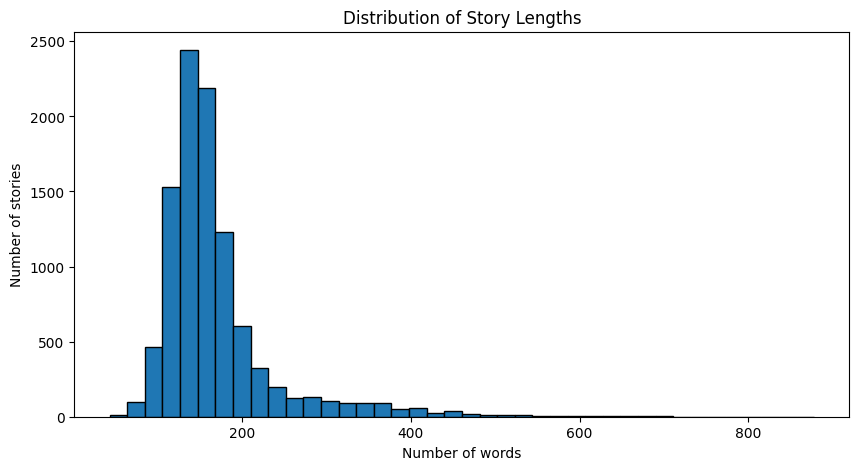

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_train["word_count"],
    bins=40,
    edgecolor="black"
)

plt.title("Distribution of Story Lengths")
plt.xlabel("Number of words")
plt.ylabel("Number of stories")
plt.show()

**First Tokenizer**

In [15]:
EOS_TOKEN = 256
VOCAB_SIZE = 257

def encode(text):
    return list(text.encode("utf-8"))

def decode(tokens):
    valid_tokens = [
        token for token in tokens
        if 0 <= token < 256
    ]

    return bytes(valid_tokens).decode(
        "utf-8",
        errors="replace"
    )

text = "Hello world"

tokens = encode(text)

print("Original:", text)
print("Tokens:", tokens)
print("Decoded:", decode(tokens))
print("Vocabulary size:", VOCAB_SIZE)

Original: Hello world
Tokens: [72, 101, 108, 108, 111, 32, 119, 111, 114, 108, 100]
Decoded: Hello world
Vocabulary size: 257


In [16]:
import torch
def tokenize_dataset(samples):
    all_tokens = []

    for sample in samples:
        text = sample["text"]

        all_tokens.extend(encode(text))
        all_tokens.append(EOS_TOKEN)

    return torch.tensor(
        all_tokens,
        dtype=torch.long
    )


train_tokens = tokenize_dataset(train_samples)
val_tokens = tokenize_dataset(validation_samples)
test_tokens = tokenize_dataset(test_samples)

print("Train tokens:", train_tokens.shape)
print("Validation tokens:", val_tokens.shape)
print("Test tokens:", test_tokens.shape)

Train tokens: torch.Size([8702527])
Validation tokens: torch.Size([793375])
Test tokens: torch.Size([802542])


In [17]:
#Créer un batch
BLOCK_SIZE = 128
BATCH_SIZE = 32

def get_batch(
    data,
    batch_size=BATCH_SIZE,
    block_size=BLOCK_SIZE
):

    indices = torch.randint(
        0,
        len(data) - block_size,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i + block_size]
        for i in indices
    ])

    y = torch.stack([
        data[i + 1:i + block_size + 1]
        for i in indices
    ])

    return x.to(device), y.to(device)

x, y = get_batch(train_tokens)

print("Input shape:", x.shape)
print("Target shape:", y.shape)
print("Device:", x.device)

Input shape: torch.Size([32, 128])
Target shape: torch.Size([32, 128])
Device: cuda:0


**Implémentation du modèle**

In [18]:
import torch.nn as nn
import torch.nn.functional as F

class MiniGPT(nn.Module):

    def __init__(
        self,
        vocab_size=257,
        block_size=128,
        n_embd=128,
        n_head=4,
        n_layer=4,
        dropout=0.1
    ):

        super().__init__()

        self.block_size = block_size

        self.token_embedding = nn.Embedding(
            vocab_size, n_embd
        )

        self.position_embedding = nn.Embedding(
            block_size, n_embd
        )

        layer = nn.TransformerEncoderLayer(
            d_model=n_embd,
            nhead=n_head,
            dim_feedforward=4 * n_embd,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=n_layer
        )

        self.layer_norm = nn.LayerNorm(n_embd)

        self.lm_head = nn.Linear(
            n_embd,
            vocab_size
        )

        self.apply(self._init_weights)

    def _init_weights(self, module):

        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(
                module.weight,
                mean=0.0,
                std=0.02
            )

        if isinstance(module, nn.Linear):
            if module.bias is not None:
                nn.init.zeros_(module.bias)

        if isinstance(module, nn.MultiheadAttention):
            nn.init.xavier_uniform_(
                module.in_proj_weight
            )

    def forward(self, idx, targets=None):

        B, T = idx.shape

        positions = torch.arange(
            T,
            device=idx.device
        )

        tok_emb = self.token_embedding(idx)

        pos_emb = self.position_embedding(
            positions
        )

        x = tok_emb + pos_emb

        causal_mask = torch.triu(
            torch.ones(
                T, T,
                device=idx.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        x = self.transformer(
            x,
            mask=causal_mask
        )

        x = self.layer_norm(x)

        logits = self.lm_head(x)

        loss = None

        if targets is not None:

            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss

In [19]:
#Initialiser mini-gpt
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model = MiniGPT().to(device)

num_params = sum(
    p.numel()
    for p in model.parameters()
)

print("Model:", model.__class__.__name__)
print("Number of parameters:", num_params)
print(f"Parameters: {num_params / 1e6:.3f} M")

Model: MiniGPT
Number of parameters: 875777
Parameters: 0.876 M


/tmp/ipykernel_9747/4044784157.py:38: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


**Premier test**

In [20]:
x, y = get_batch(train_tokens)

logits, loss = model(x, y)

print("Input shape:", x.shape)
print("Target shape:", y.shape)
print("Logits shape:", logits.shape)
print("Initial loss:", loss.item())

Input shape: torch.Size([32, 128])
Target shape: torch.Size([32, 128])
Logits shape: torch.Size([32, 128, 257])
Initial loss: 5.600825309753418


In [21]:
# Tester une mise à jour du poids
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3
)

model.train()

optimizer.zero_grad()

logits, loss = model(x, y)

print("Loss before:", loss.item())

loss.backward()

optimizer.step()

model.eval()

with torch.no_grad():
    _, new_loss = model(x, y)

print("Loss after:", new_loss.item())

Loss before: 5.598128795623779
Loss after: 5.147469520568848


In [22]:
# verifier si on utilise les mêmes histoires dans l'entraînement et dans l'évaluation
train_texts = {s["text"] for s in train_samples}
val_texts = {s["text"] for s in validation_samples}
test_texts = {s["text"] for s in test_samples}

print("Train / Validation:",
      len(train_texts & val_texts))

print("Train / Test:",
      len(train_texts & test_texts))

print("Validation / Test:",
      len(val_texts & test_texts))

Train / Validation: 0
Train / Test: 0
Validation / Test: 0


**Notre configuration initiale**

In [23]:
import json

baseline_config = {
    "model": "MiniGPT",
    "dataset": "roneneldan/TinyStories",
    "tokenizer": "byte-level",
    "vocab_size": 257,
    "block_size": 128,
    "n_embd": 128,
    "n_head": 4,
    "n_layer": 4,
    "dropout": 0.1,
    "batch_size": 32,
    "learning_rate": 0.001,
    "seed": 42
}

config_path = PROJECT_DIR / "configs" / "baseline.json"

with open(config_path, "w") as f:
    json.dump(baseline_config, f, indent=4)

print("Saved:", config_path)

Saved: /content/drive/MyDrive/memory-augmented-autoresearch/configs/baseline.json
